In [ ]:
import pandas as pd
import numpy as np
import time
import tracemalloc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.model_selection import GridSearchCV'
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import accuracy_score, mean_squared_error
import joblib

# 1. Carregar e Dividir Dados

In [11]:
df_class = pd.read_csv('../data/processed/dataset_classification.csv')
X_class = df_class.drop(columns=['TARGET'])
y_class = df_class['TARGET']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42, stratify=y_class
)

df_reg = pd.read_csv('../data/processed/dataset_regression.csv')
X_reg = df_reg.drop(columns=['TARGET'])
y_reg = df_reg['TARGET']
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)
print("Dados carregados com sucesso!")

Dados carregados com sucesso!


# 2. ENSEMBLE CLASSIFICAÇÃO: Ajuste e Treino

In [12]:
print("--- 1. Ajustando Classificação (GridSearchCV Otimizado) ---")
param_grid_c = {'n_estimators': [50, 100], 'max_depth': [5, 10]}

grid_rf_c = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_c, cv=5, scoring='accuracy')
grid_rf_c.fit(X_train_c, y_train_c)
best_rf_c = grid_rf_c.best_estimator_

grid_gb_c = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid_c, cv=5, scoring='accuracy')
grid_gb_c.fit(X_train_c, y_train_c)
best_gb_c = grid_gb_c.best_estimator_

print(f"Melhores parâmetros RF: {grid_rf_c.best_params_}")
print(f"Acurácia Teste RF: {accuracy_score(y_test_c, best_rf_c.predict(X_test_c)):.4f}")
print(f"Acurácia Teste GB: {accuracy_score(y_test_c, best_gb_c.predict(X_test_c)):.4f}")

--- 1. Ajustando Classificação (GridSearchCV Otimizado) ---
Melhores parâmetros RF: {'max_depth': 10, 'n_estimators': 100}
Acurácia Teste RF: 0.8013
Acurácia Teste GB: 0.9465


# 3. Gráficos Obrigatórios (Random Forest)

/tmp/ipykernel_18387/1188505232.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=best_rf_c.feature_importances_, y=X_class.columns, palette='magma')


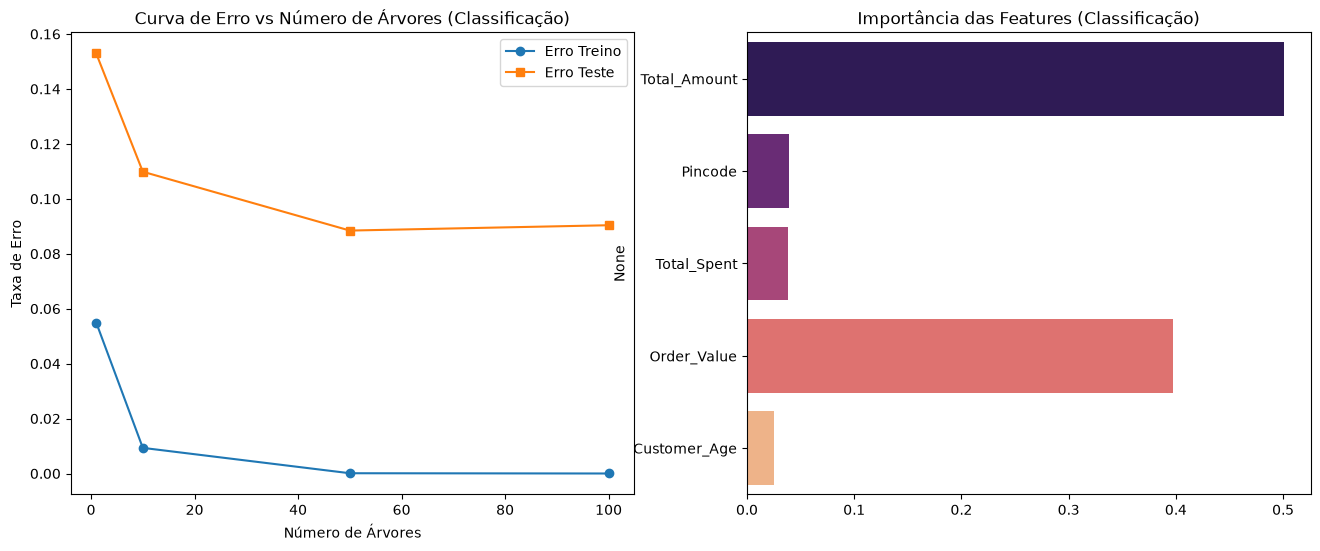

Modelos de Classificação salvos com sucesso!


In [13]:
n_trees = [1, 10, 50, 100]
train_errors, test_errors = [], []
for n in n_trees:
    rf_temp = RandomForestClassifier(n_estimators=n, random_state=42)
    rf_temp.fit(X_train_c, y_train_c)
    train_errors.append(1 - accuracy_score(y_train_c, rf_temp.predict(X_train_c)))
    test_errors.append(1 - accuracy_score(y_test_c, rf_temp.predict(X_test_c)))

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
plt.plot(n_trees, train_errors, label='Erro Treino', marker='o')
plt.plot(n_trees, test_errors, label='Erro Teste', marker='s')
plt.title('Curva de Erro vs Número de Árvores (Classificação)')
plt.xlabel('Número de Árvores')
plt.ylabel('Taxa de Erro')
plt.legend()

plt.subplot(1, 2, 2)
sns.barplot(x=best_rf_c.feature_importances_, y=X_class.columns, palette='magma')
plt.title('Importância das Features (Classificação)')
plt.savefig('../reports/figures/rf_classification_analysis.png', bbox_inches='tight')
plt.show()

# Salvando os modelos de classificação
joblib.dump(best_rf_c, '../data/processed/best_rf_c.pkl')
joblib.dump(best_gb_c, '../data/processed/best_gb_c.pkl')
print("Modelos de Classificação salvos com sucesso!")

# 4. ENSEMBLE REGRESSÃO: Ajuste e Treino

In [14]:
print("--- 2. Ajustando Regressão (GridSearchCV Otimizado) ---")
param_grid_r = {'n_estimators': [50, 100], 'max_depth': [5, 10]}

grid_rf_r = GridSearchCV(RandomForestRegressor(random_state=42), param_grid_r, cv=5, scoring='neg_mean_squared_error')
grid_rf_r.fit(X_train_r, y_train_r)
best_rf_r = grid_rf_r.best_estimator_

grid_gb_r = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid_r, cv=5, scoring='neg_mean_squared_error')
grid_gb_r.fit(X_train_r, y_train_r)
best_gb_r = grid_gb_r.best_estimator_

print(f"Melhores parâmetros RF Regressão: {grid_rf_r.best_params_}")
print(f"RMSE Teste RF: {np.sqrt(mean_squared_error(y_test_r, best_rf_r.predict(X_test_r))):.4f}")
print(f"RMSE Teste GB: {np.sqrt(mean_squared_error(y_test_r, best_gb_r.predict(X_test_r))):.4f}")

--- 2. Ajustando Regressão (GridSearchCV Otimizado) ---
Melhores parâmetros RF Regressão: {'max_depth': 10, 'n_estimators': 100}
RMSE Teste RF: 0.0383
RMSE Teste GB: 0.0364


# 5. GRÁFICOS OBRIGATÓRIOS (Random Forest)

/tmp/ipykernel_18387/2818835760.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=best_rf_r.feature_importances_, y=X_reg.columns, palette='viridis')


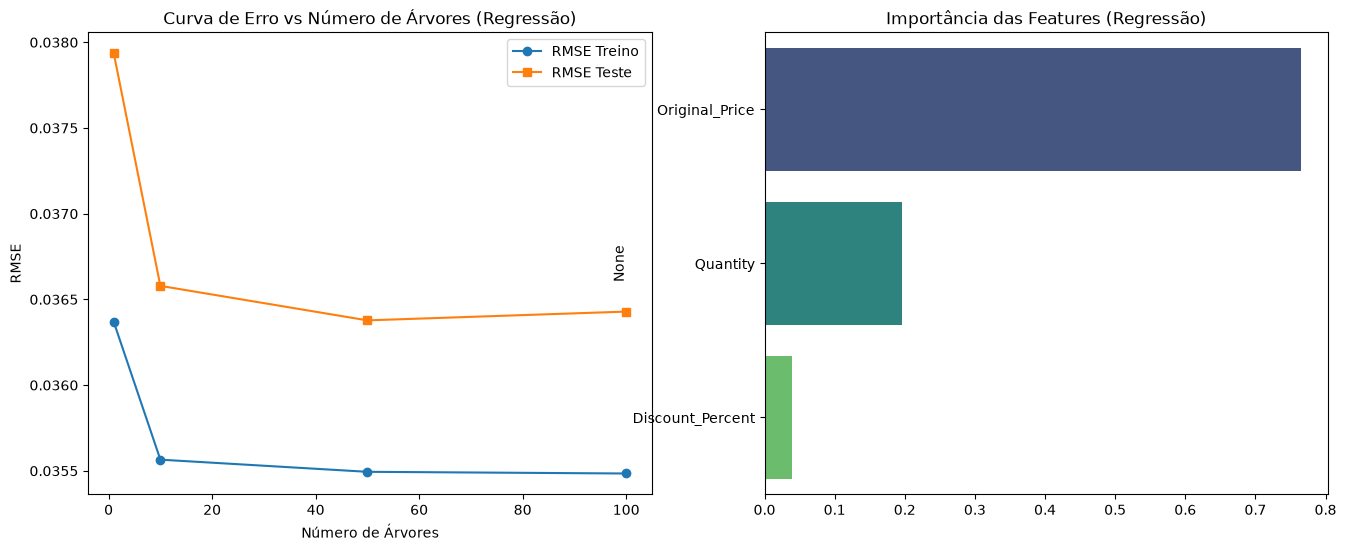

Modelos de Regressão salvos com sucesso!


In [15]:
train_errors_r, test_errors_r = [], []
for n in n_trees:
    rf_temp_r = RandomForestRegressor(n_estimators=n, random_state=42)
    rf_temp_r.fit(X_train_r, y_train_r)
    train_errors_r.append(np.sqrt(mean_squared_error(y_train_r, rf_temp_r.predict(X_train_r))))
    test_errors_r.append(np.sqrt(mean_squared_error(y_test_r, rf_temp_r.predict(X_test_r))))

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
plt.plot(n_trees, train_errors_r, label='RMSE Treino', marker='o')
plt.plot(n_trees, test_errors_r, label='RMSE Teste', marker='s')
plt.title('Curva de Erro vs Número de Árvores (Regressão)')
plt.xlabel('Número de Árvores')
plt.ylabel('RMSE')
plt.legend()

plt.subplot(1, 2, 2)
sns.barplot(x=best_rf_r.feature_importances_, y=X_reg.columns, palette='viridis')
plt.title('Importância das Features (Regressão)')
plt.savefig('../reports/figures/rf_regression_analysis.png', bbox_inches='tight')
plt.show()

# Salvando os modelos de regressão
joblib.dump(best_rf_r, '../data/processed/best_rf_r.pkl')
joblib.dump(best_gb_r, '../data/processed/best_gb_r.pkl')
print("Modelos de Regressão salvos com sucesso!")
